# 1. Import libraries 

In [17]:
import tensorflow as tf 
from tensorflow.keras import layers, models, datasets 
import matplotlib.pyplot as plt 
import numpy as np 
import tensorflow_datasets as tfds
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from collections import Counter

# 2. Load data

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.cifar100.load_data()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [3]:
x_train.shape 

(50000, 32, 32, 3)

In [4]:
x_test.shape

(10000, 32, 32, 3)

In [5]:
y_train.shape

(50000, 1)

In [6]:
y_test.shape

(10000, 1)

In [7]:
labels_cifar100 = [
    "apple", "aquarium_fish", "baby", "bear", "beaver",
    "bed", "bee", "beetle", "bicycle", "bottle",
    "bowl", "boy", "bridge", "bus", "butterfly",
    "camel", "can", "castle", "caterpillar", "cattle",
    "chair", "chimpanzee", "clock", "cloud", "cockroach",
    "couch", "crab", "crocodile", "cup", "dinosaur",
    "dolphin", "elephant", "flatfish", "forest", "fox",
    "girl", "hamster", "house", "kangaroo", "keyboard",
    "lamp", "lawn_mower", "leopard", "lion", "lizard",
    "lobster", "man", "maple_tree", "motorcycle", "mountain",
    "mouse", "mushroom", "oak_tree", "orange", "orchid",
    "otter", "palm_tree", "pear", "pickup_truck", "pine_tree",
    "plain", "plate", "poppy", "porcupine", "possum",
    "rabbit", "raccoon", "ray", "road", "rocket",
    "rose", "sea", "seal", "shark", "shrew",
    "skunk", "skyscraper", "snail", "snake", "spider",
    "squirrel", "streetcar", "sunflower", "sweet_pepper", "table",
    "tank", "telephone", "television", "tiger", "tractor",
    "train", "trout", "tulip", "turtle", "wardrobe",
    "whale", "willow_tree", "wolf", "woman", "worm"
]

In [9]:
num_classes = len(labels_cifar100)
num_classes

100

# 3. Preprocessing data 

In [10]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

# 4. Define AlexNet model

In [11]:
model = models.Sequential()
# Block 1 
model.add(layers.Conv2D(64, (3,3), padding='same', input_shape=(32, 32, 3)))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))

model.add(layers.Conv2D(64, (3,3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))

model.add(layers.MaxPooling2D(pool_size=(2,2)))
model.add(layers.Dropout(0.25))
# Block 2
model.add(layers.Conv2D(128, (3,3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))

model.add(layers.Conv2D(128, (3,3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))

model.add(layers.MaxPooling2D(pool_size=(2,2)))
model.add(layers.Dropout(0.25))

# Block 3
model.add(layers.Conv2D(256, (3,3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))

model.add(layers.Conv2D(256, (3,3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))

model.add(layers.MaxPooling2D(pool_size=(2,2)))
model.add(layers.Dropout(0.25))

# Flatten
model.add(layers.Flatten())

# FC Layer
model.add(layers.Dense(512))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))
model.add(layers.Dropout(0.5))

# Output
model.add(layers.Dense(100, activation='softmax')) 

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1779530175.915774    1447 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [13]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
history = model.fit(x_train, y_train,
                    batch_size=128,
                    epochs=15,
                    callbacks=[early_stop, reduce_lr],
                    validation_split=0.2,
                    verbose=1)

Epoch 1/15


I0000 00:00:1779530903.905888   17198 service.cc:153] XLA service 0x7ee5ac041040 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779530903.905968   17198 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1779530904.001253   17198 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1779530904.762818   17198 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1779530907.748464   17198 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6887__.90
I0000 00:00:1779530910.820805   25270 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 8540 bytes spill stores, 8520 bytes spill loads

I0000 00:00:1779530915.169572   25265 subprocess_compilation.cc:348] ptxas wa

  1/313 ━━━━━━━━━━━━━━━━━━━━ 2:16:19 26s/step - accuracy: 0.0000e+00 - loss: 5.5312

I0000 00:00:1779530925.791199   17198 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.0780 - loss: 4.2931

I0000 00:00:1779530944.881508   17198 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6887__.90
I0000 00:00:1779530946.179274   26022 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 8416 bytes spill stores, 8424 bytes spill loads



313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 141ms/step - accuracy: 0.1240 - loss: 3.8724 - val_accuracy: 0.0519 - val_loss: 4.8617 - learning_rate: 0.0010
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.2602 - loss: 2.9793 - val_accuracy: 0.2888 - val_loss: 2.8929 - learning_rate: 0.0010
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.3555 - loss: 2.4840 - val_accuracy: 0.3511 - val_loss: 2.4932 - learning_rate: 0.0010
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.4182 - loss: 2.1843 - val_accuracy: 0.3705 - val_loss: 2.4997 - learning_rate: 0.0010
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - accuracy: 0.4631 - loss: 1.9853 - val_accuracy: 0.4605 - val_loss: 2.0252 - learning_rate: 0.0010
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 60ms/step - accuracy: 0.5020 - loss: 1.8190 - val_accuracy: 0.4010 - val_loss: 2.3867 - learning_rate: 0.0010
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - accuracy: 0.5311 - loss: 1.677

In [14]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}')

Test Loss: 1.4458, Test Accuracy: 0.6028


# 5. Visualize the result

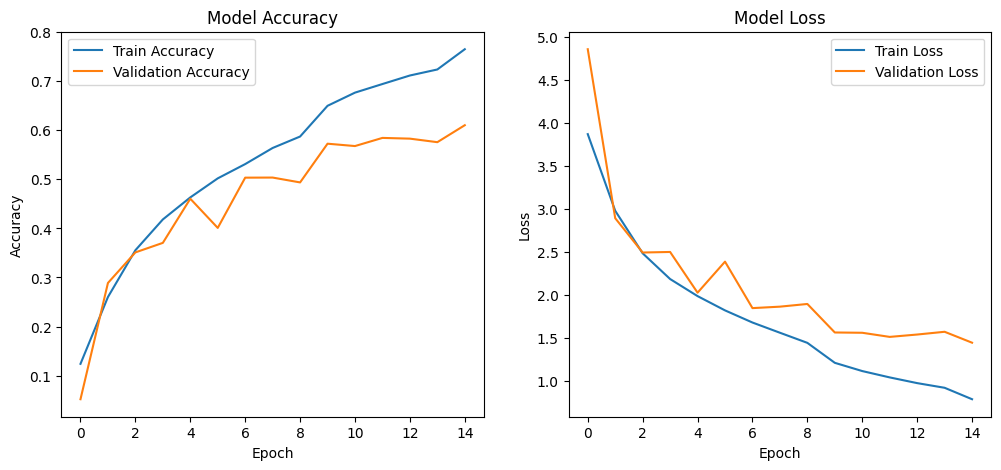

In [15]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


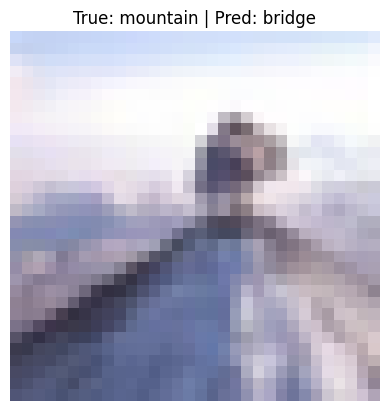

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


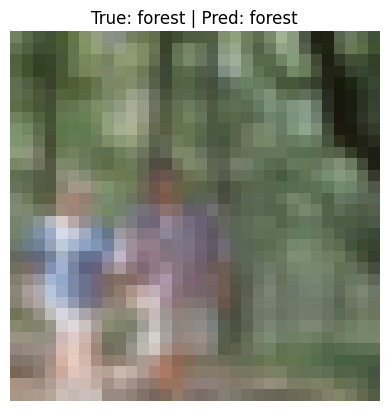

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


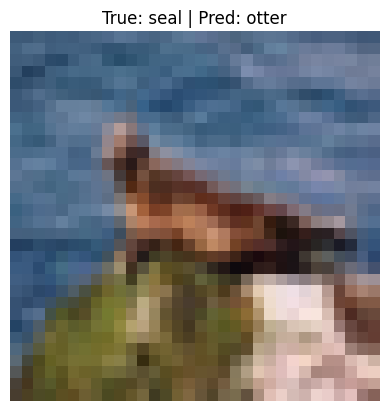

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


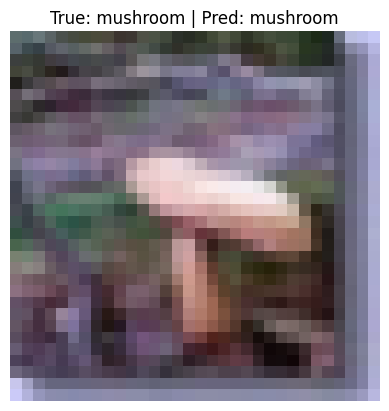

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


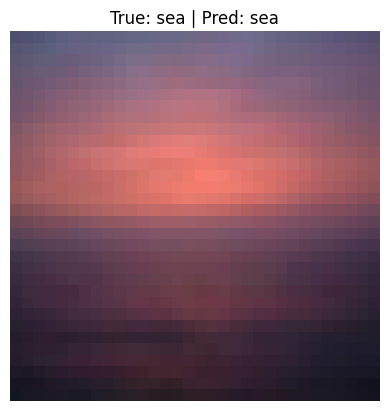

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


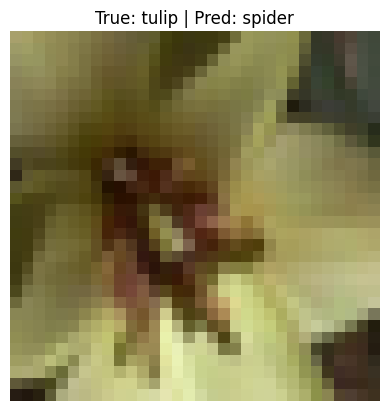

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


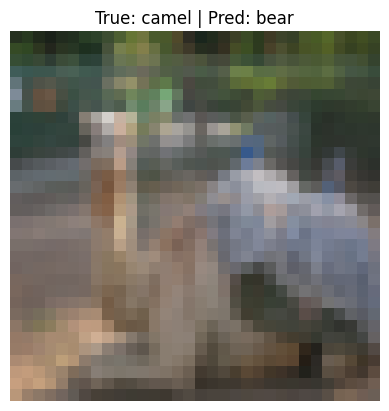

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


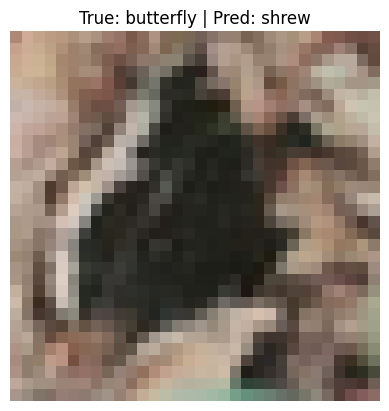

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


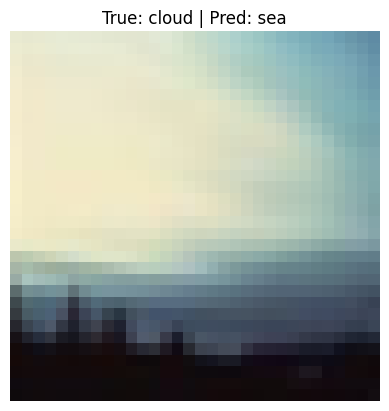

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


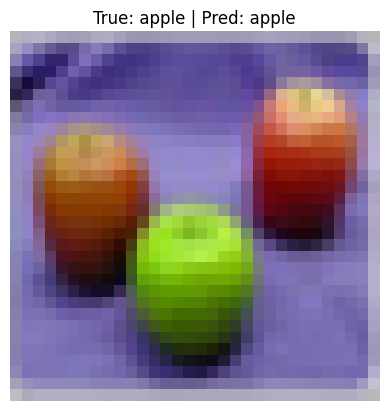

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


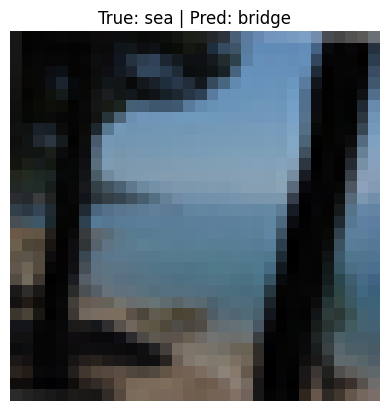

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


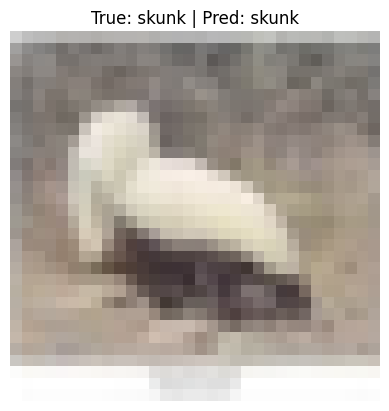

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


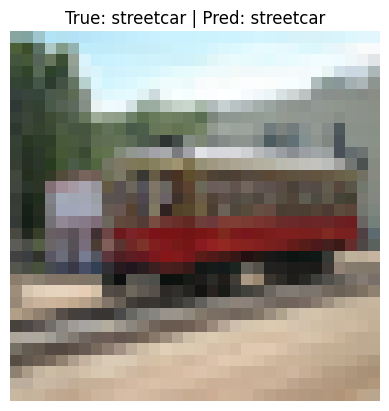

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


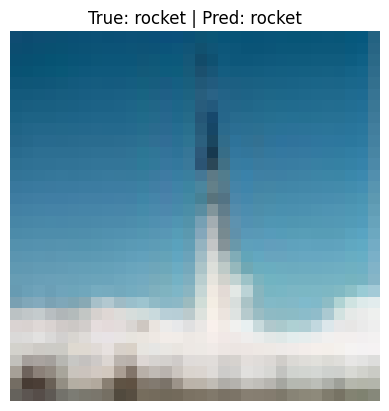

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


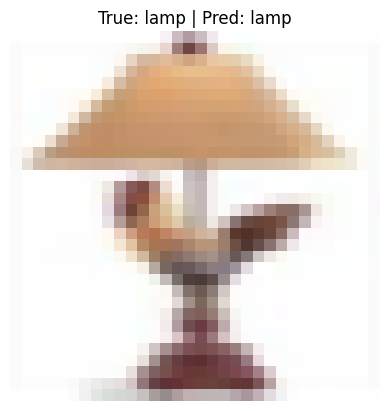

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


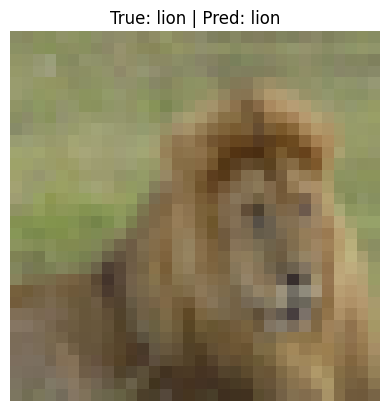

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


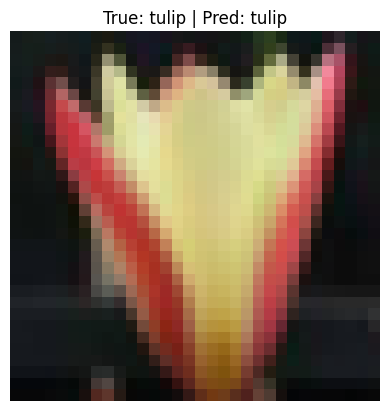

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


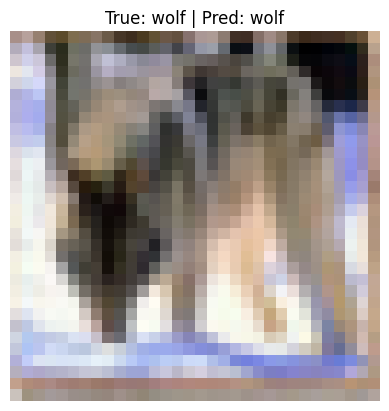

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


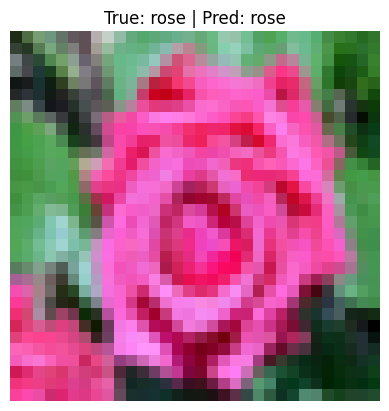

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


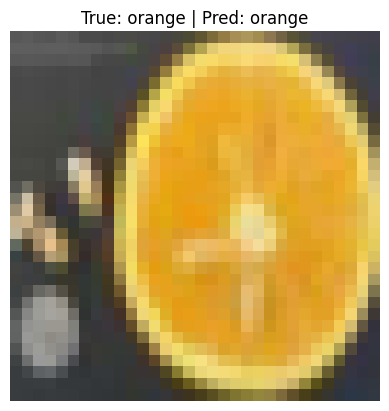

In [16]:
def plot_predictions2(index):
    img = x_test[index]
    true_label = labels_cifar100[np.argmax(y_test[index])]
    pred_probs = model.predict(np.expand_dims(img, axis=0))
    pred_label = labels_cifar100[np.argmax(pred_probs)]

    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions2(i)

# 6. Refine model 

In [18]:
model1 = models.Sequential()

# Block 1 — 2 Conv giữ spatial info, MaxPool giảm 32→16
model1.add(layers.Conv2D(64, (3,3), padding='same', input_shape=(32, 32, 3),
                        kernel_initializer='he_normal'))  # he_normal tốt hơn glorot_uniform cho ReLU
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))

model1.add(layers.Conv2D(64, (3,3), padding='same',
                        kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))

model1.add(layers.MaxPooling2D(pool_size=(2,2)))  # 32x32 → 16x16
model1.add(layers.Dropout(0.2))  # nhẹ ở block đầu, feature chưa abstract nhiều

# Block 2 — tăng filter 128, MaxPool giảm 16→8
model1.add(layers.Conv2D(128, (3,3), padding='same',
                        kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))

model1.add(layers.Conv2D(128, (3,3), padding='same',
                        kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))

model1.add(layers.MaxPooling2D(pool_size=(2,2)))  # 16x16 → 8x8
model1.add(layers.Dropout(0.3))  # tăng dropout dần theo độ sâu

# Block 3 — tăng filter 256, bỏ MaxPool để giữ spatial info cho GAP
model1.add(layers.Conv2D(256, (3,3), padding='same',
                        kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))

model1.add(layers.Conv2D(256, (3,3), padding='same',
                        kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))

# GAP thay Flatten: trung bình mỗi feature map 8x8 → 1 giá trị
# giảm params đáng kể (8x8x256=16384 → 256), chống overfit tốt hơn
model1.add(layers.GlobalAveragePooling2D())
model1.add(layers.Dropout(0.4))

# FC layer 1 — học high-level combination từ 256 features
model1.add(layers.Dense(512, kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))
model1.add(layers.Dropout(0.5))  # dropout mạnh nhất ở FC để chống overfit

# FC layer 2 — thêm mới so với model cũ, giảm dần 512→256 trước output
model1.add(layers.Dense(256, kernel_initializer='he_normal'))
model1.add(layers.BatchNormalization())
model1.add(layers.Activation('relu'))
model1.add(layers.Dropout(0.3))

# Output — 100 classes, softmax cho xác suất tổng = 1
model1.add(layers.Dense(100, activation='softmax'))

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 8, 8, 256)      │             

 Total params: 1,440,676 (5.50 MB)

 Trainable params: 1,437,348 (5.48 MB)

 Non-trainable params: 3,328 (13.00 KB)

In [22]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
)
model1.compile(
    loss='categorical_crossentropy',  # hoặc categorical tùy label của bạn
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    metrics=['accuracy']
)
datagen.fit(x_train)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
epochs = 20 
history2 = model1.fit(datagen.flow(x_train, y_train, batch_size=128),
                     epochs=epochs, 
                     callbacks=[early_stop, reduce_lr], 
                     validation_data=(x_test, y_test), 
                     verbose=2)

Epoch 1/20


I0000 00:00:1779532286.782433   17197 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_42946__.92
I0000 00:00:1779532299.754119   17199 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_42946__.92
I0000 00:00:1779532303.019733   17199 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


391/391 - 63s - 160ms/step - accuracy: 0.0562 - loss: 4.2048 - val_accuracy: 0.0738 - val_loss: 4.2081 - learning_rate: 0.0010
Epoch 2/20
391/391 - 23s - 59ms/step - accuracy: 0.1134 - loss: 3.6826 - val_accuracy: 0.0737 - val_loss: 4.1980 - learning_rate: 0.0010
Epoch 3/20
391/391 - 20s - 50ms/step - accuracy: 0.1625 - loss: 3.3894 - val_accuracy: 0.1719 - val_loss: 3.5290 - learning_rate: 0.0010
Epoch 4/20
391/391 - 23s - 59ms/step - accuracy: 0.2042 - loss: 3.1496 - val_accuracy: 0.2142 - val_loss: 3.1538 - learning_rate: 0.0010
Epoch 5/20
391/391 - 23s - 59ms/step - accuracy: 0.2399 - loss: 2.9638 - val_accuracy: 0.2467 - val_loss: 2.9510 - learning_rate: 0.0010
Epoch 6/20
391/391 - 20s - 50ms/step - accuracy: 0.2657 - loss: 2.8132 - val_accuracy: 0.2135 - val_loss: 3.4834 - learning_rate: 0.0010
Epoch 7/20
391/391 - 23s - 59ms/step - accuracy: 0.2937 - loss: 2.6780 - val_accuracy: 0.3000 - val_loss: 2.7210 - learning_rate: 0.0010
Epoch 8/20
391/391 - 20s - 50ms/step - accuracy: 0.

In [23]:
loss, acc = model1.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}')

Test Loss: 1.8255, Test Accuracy: 0.4863


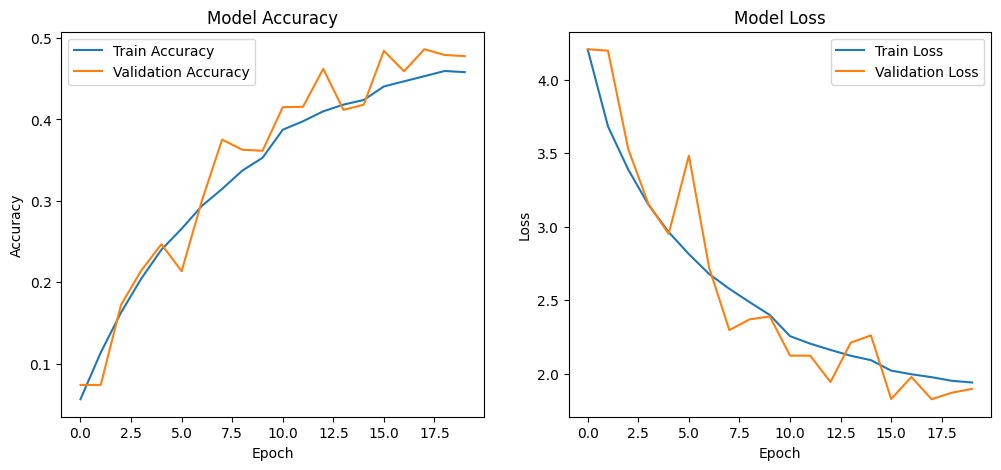

In [24]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history2.history['loss'], label='Train Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


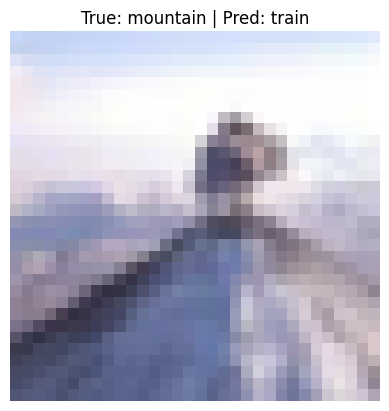

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


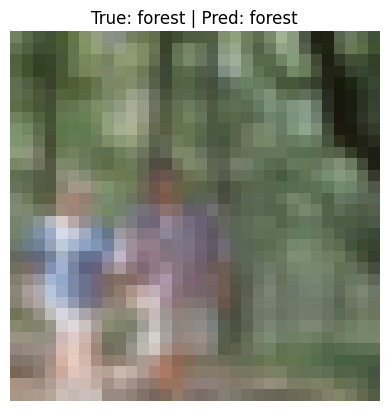

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


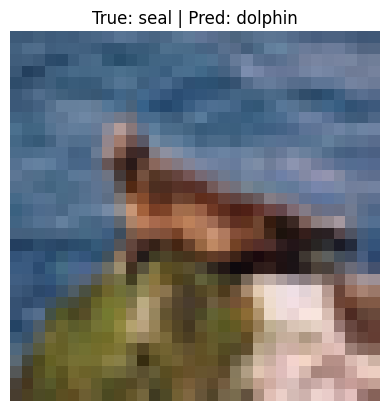

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


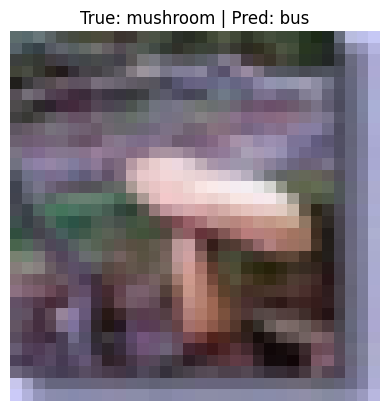

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


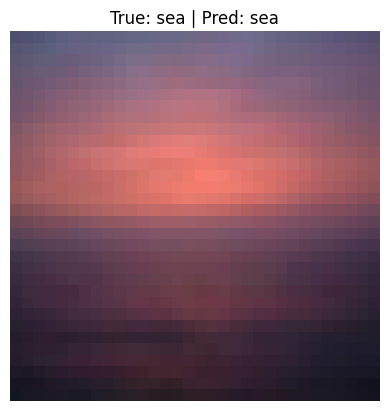

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


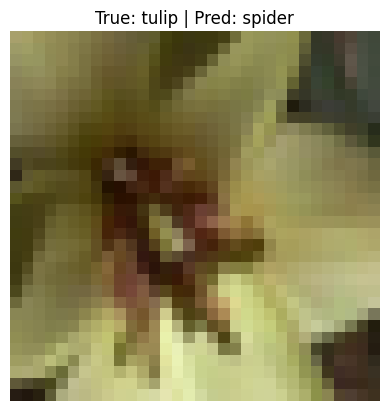

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


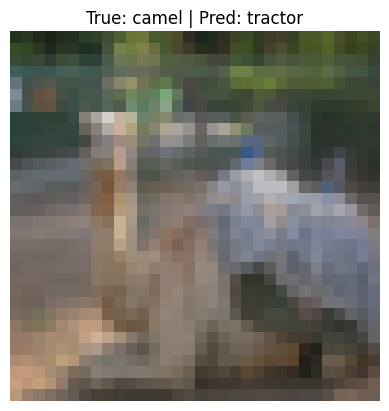

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


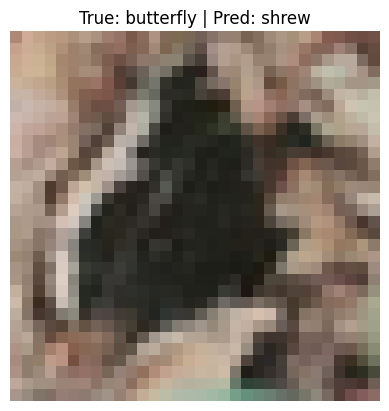

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


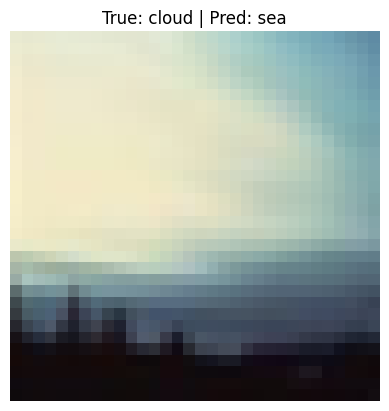

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


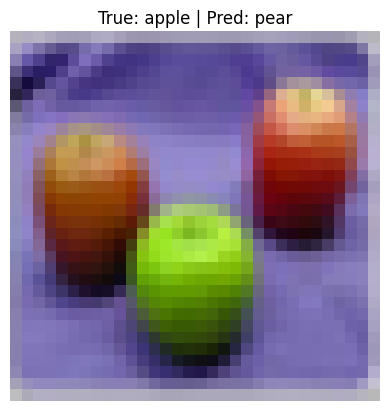

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


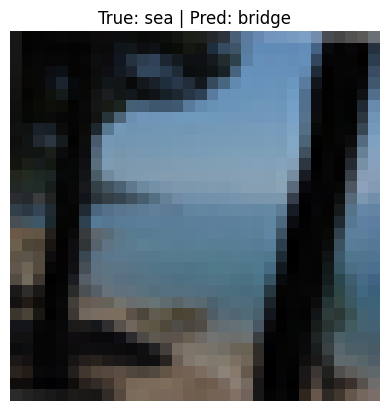

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


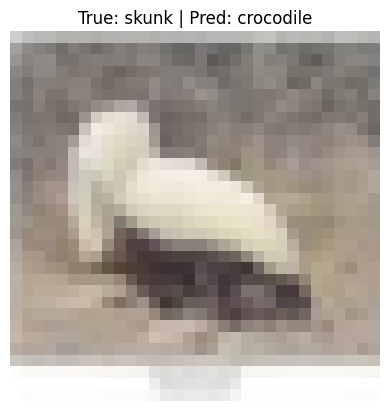

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


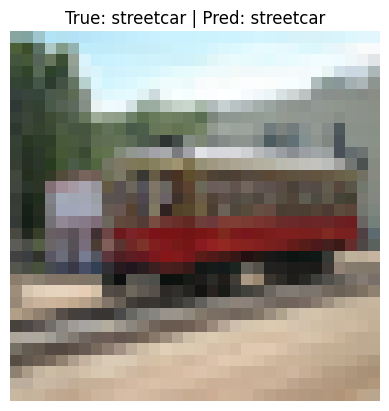

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


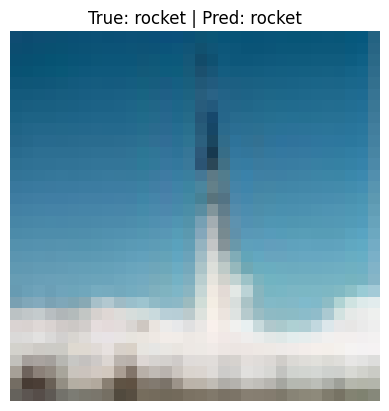

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


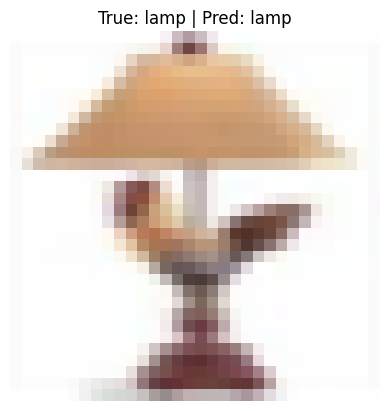

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


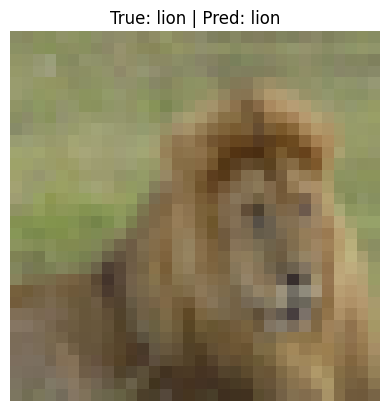

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


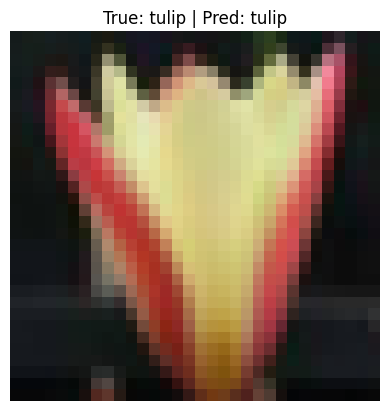

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


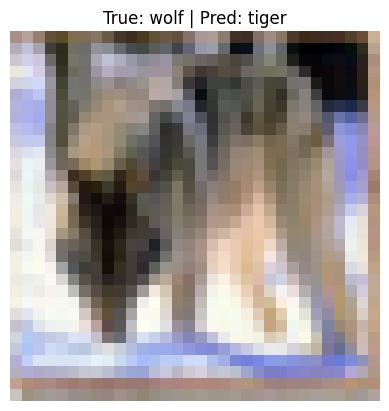

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


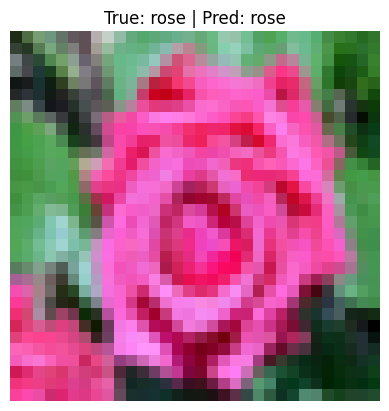

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


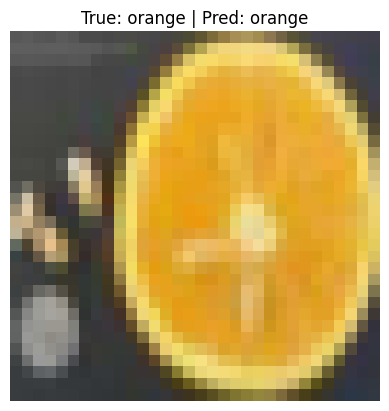

In [25]:
def plot_predictions(index):
    img = x_test[index]
    true_label = labels_cifar100[np.argmax(y_test[index])]
    pred_probs = model1.predict(np.expand_dims(img, axis=0))
    pred_label = labels_cifar100[np.argmax(pred_probs)]

    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions(i)